In [1]:
# Entorno común a todos los notebooks. Se corre desde codigo/ para usar las mismas rutas que los scripts.
import os
import sys
import time
from dataclasses import replace
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage, signal

from estadios.clasificacion import reglas
from estadios.comun.config import Config, ConfigDescriptores
from estadios.comun.constantes import (
    CANALES_EEG, ECG, EEG_C4, EEG_F4, EEG_O2, EOG_E1, EOG_E2, N1, N2, N3, NOMBRES_ESTADIOS, R, W,
)
from estadios.comun.contratos import RegistroPreprocesado
from estadios.comun.sintetico import registro_sintetico
from estadios.datos.carga import DIR_REGISTROS, cargar_registro, ids_disponibles
from estadios.datos.particion import particion_por_paciente
from estadios.descriptores import espectro, hrv, ondas_lentas
from estadios.evaluacion import hipotesis, metricas
from estadios.clasificacion.modelo import ModeloEstadios
from estadios.pipeline import obtener_tabla, preprocesar
from estadios.preprocesamiento import cardiaco, exploratorio, filtrado, ocular, qrs, segmentacion
from estadios.preprocesamiento.segmentacion import segmentar

USAR_DATOS_REALES = len(ids_disponibles()) > 0
IDS = particion_por_paciente(ids_disponibles())[0] if USAR_DATOS_REALES else []
EJEMPLO = "SN004" if "SN004" in IDS else (IDS[0] if IDS else None)
CFG = Config().preprocesamiento
print(f"Pacientes de entrenamiento disponibles {len(IDS)}")

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8981", "lines.linewidth": 1.2, "legend.frameon": False,
})
AZUL, NARANJA, AGUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRIS = "#52514e"
COLOR_ESTADIO = {W: AZUL, N1: NARANJA, N2: AGUA, N3: AMARILLO, R: MAGENTA}


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def pacientes(n=None):
    """Recorre los pacientes de entrenamiento de a uno, para no tener toda la base en memoria."""
    if not USAR_DATOS_REALES:
        for semilla in range(3):
            yield registro_sintetico(semilla=semilla)
        return
    for id_registro in IDS[:n]:
        yield cargar_registro(id_registro)


def ejemplo():
    return cargar_registro(EJEMPLO) if EJEMPLO else registro_sintetico()


def corto(canal):
    return canal.split()[1].split("-")[0]


N_DETALLE = 12  # Pacientes usados en los análisis por estadio.

In [2]:
# Entorno común a todos los notebooks. Se corre desde codigo/ para usar las mismas rutas que los scripts.
import os
import sys
import time
from dataclasses import replace
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage, signal

from estadios.clasificacion import reglas
from estadios.comun.config import Config, ConfigDescriptores
from estadios.comun.constantes import (
    CANALES_EEG, ECG, EEG_C4, EEG_F4, EEG_O2, EOG_E1, EOG_E2, N1, N2, N3, NOMBRES_ESTADIOS, R, W,
)
from estadios.comun.contratos import RegistroPreprocesado
from estadios.comun.sintetico import registro_sintetico
from estadios.datos.carga import DIR_REGISTROS, cargar_registro, ids_disponibles
from estadios.datos.particion import particion_por_paciente
from estadios.descriptores import espectro, hrv, ondas_lentas
from estadios.evaluacion import hipotesis
from estadios.clasificacion.modelo import ModeloEstadios
from estadios.pipeline import obtener_tabla, preprocesar
from estadios.preprocesamiento import cardiaco, exploratorio, filtrado, ocular, qrs, segmentacion
from estadios.preprocesamiento.segmentacion import segmentar

USAR_DATOS_REALES = len(ids_disponibles()) > 0
IDS = particion_por_paciente(ids_disponibles())[0] if USAR_DATOS_REALES else []
EJEMPLO = "SN004" if "SN004" in IDS else (IDS[0] if IDS else None)
CFG = Config().preprocesamiento
print(f"Pacientes de entrenamiento disponibles {len(IDS)}")

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8981", "lines.linewidth": 1.2, "legend.frameon": False,
})
AZUL, NARANJA, AGUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRIS = "#52514e"
COLOR_ESTADIO = {W: AZUL, N1: NARANJA, N2: AGUA, N3: AMARILLO, R: MAGENTA}


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def pacientes(n=None):
    """Recorre los pacientes de entrenamiento de a uno, para no tener toda la base en memoria."""
    if not USAR_DATOS_REALES:
        for semilla in range(3):
            yield registro_sintetico(semilla=semilla)
        return
    for id_registro in IDS[:n]:
        yield cargar_registro(id_registro)


def ejemplo():
    return cargar_registro(EJEMPLO) if EJEMPLO else registro_sintetico()


def corto(canal):
    return canal.split()[1].split("-")[0]


N_DETALLE = 12  # Pacientes usados en los análisis por estadio.

Pacientes de entrenamiento disponibles 56


## 1. Análisis exploratorio

### 1.1 Frecuencia de la línea eléctrica

Antes de poner un notch hay que saber en qué frecuencia está la interferencia, porque depende del país donde se grabó la señal. Es 50 Hz en Europa y en Argentina, y 60 Hz en otros lugares como Estados Unidos.

Para cada paciente y canal calculamos el espectro de toda la noche y medimos cuántos dB sobresale cada frecuencia candidata respecto de sus vecinas. Usamos la mediana entre segmentos para que unos pocos movimientos no dominen el resultado.

Cuántos dB sobresale cada frecuencia respecto de sus vecinas


,50 Hz,60 Hz
min,0.1,-0.4
25%,9.4,0.0
50%,17.5,0.1
75%,27.6,0.2
max,54.2,3.4


Pares paciente y canal con más de 3 dB en 50 Hz 95%
Pares paciente y canal con más de 3 dB en 60 Hz 1%


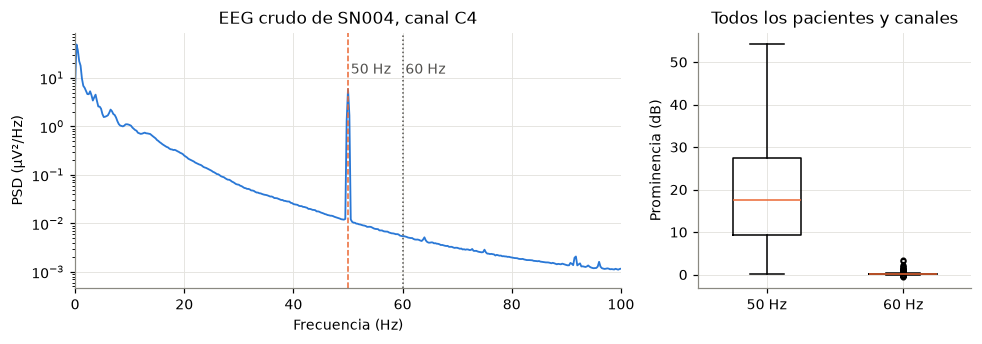

In [3]:
LIMITE_UV = 799.0  # Borde del rango físico de ±800 µV que declara el encabezado EDF (sección 1.2).
filas = []
for r in pacientes():
    n_epoca = int(30 * r.fs)
    for canal in CANALES_EEG:
        f, psd = exploratorio.espectro_del_registro(r.senales[canal], r.fs)
        prominencia = exploratorio.prominencia_de_linea(f, psd)
        epocas = segmentar(r.senales[canal], r.fs, r.n_epocas)
        filas.append({
            "paciente": r.id, "canal": corto(canal),
            "50 Hz": prominencia[50.0], "60 Hz": prominencia[60.0],
            "muestras saturadas (%)": 100 * exploratorio.fraccion_cerca_del_limite(r.senales[canal], LIMITE_UV),
            "épocas con saturación (%)": 100 * np.mean(np.any(np.abs(epocas) >= LIMITE_UV, axis=1)),
        })
crudo = pd.DataFrame(filas)
print("Cuántos dB sobresale cada frecuencia respecto de sus vecinas")
display(crudo[["50 Hz", "60 Hz"]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(1))
print(f"Pares paciente y canal con más de 3 dB en 50 Hz {(crudo['50 Hz'] > 3).mean():.0%}")
print(f"Pares paciente y canal con más de 3 dB en 60 Hz {(crudo['60 Hz'] > 3).mean():.0%}")

r = ejemplo()
f, psd = exploratorio.espectro_del_registro(r.senales[EEG_C4], r.fs)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), width_ratios=[2, 1])
axs[0].semilogy(f, psd, c=AZUL)
axs[0].axvline(50, c=NARANJA, ls="--", lw=1)
axs[0].axvline(60, c=GRIS, ls=":", lw=1)
axs[0].text(50.5, psd.max() * 0.25, "50 Hz", color=GRIS)
axs[0].text(60.5, psd.max() * 0.25, "60 Hz", color=GRIS)
axs[0].set(xlim=(0, 100), xlabel="Frecuencia (Hz)", ylabel="PSD (µV²/Hz)", title=f"EEG crudo de {r.id}, canal C4")
axs[1].boxplot([crudo["50 Hz"], crudo["60 Hz"]], tick_labels=["50 Hz", "60 Hz"], widths=0.5,
               medianprops={"color": NARANJA}, flierprops={"markersize": 3})
axs[1].set(ylabel="Prominencia (dB)", title="Todos los pacientes y canales")
fig.tight_layout()
guardar(fig, "a_linea_electrica")

**Decisión.** Ponemos el notch en 50 Hz. El pico en 50 Hz supera los 3 dB en el 95 % de los pares paciente y canal. Esto coincide con el origen de la base de datos, que es un hospital de Países Bajos, donde usan 50 Hz.

### 1.2 Rango y filtros del equipo

Cada archivo EDF trae un encabezado con datos de cada canal. El rango físico es el valor en µV que corresponde al entero más grande que puede guardar el archivo. El campo de prefiltrado indica qué filtros aplicó el equipo durante la grabación.

Leemos los dos en todos los pacientes de entrenamiento. Después comparamos el espectro del canal C4 entre los pacientes que tienen distintos filtros del equipo, para ver si la diferencia se nota en la señal.

In [4]:
if USAR_DATOS_REALES:
    filas = []
    for id_registro in IDS:
        for canal, datos in exploratorio.encabezado_edf(DIR_REGISTROS / f"{id_registro}.edf").items():
            filas.append({
                "paciente": id_registro, "canal": canal,
                "rango (µV)": f"±{datos['maximo']:g}", "filtros del equipo": datos["prefiltro"],
            })
    encabezados = pd.DataFrame(filas)
    display(encabezados.groupby(["canal", "rango (µV)", "filtros del equipo"]).size().rename("pacientes").to_frame())

    # Espectro de C4 relativo a 20 Hz, para ver si se nota el pasa-bajos del equipo.
    filtro_del_equipo = encabezados[encabezados.canal == EEG_C4].set_index("paciente")["filtros del equipo"]
    marcas = [10, 30, 35, 40, 45, 60, 80]
    filas = []
    for r in pacientes():
        f, psd = exploratorio.espectro_del_registro(r.senales[EEG_C4], r.fs)
        db = 10 * np.log10(psd)
        db -= db[np.argmin(np.abs(f - 20))]
        filas.append({"filtros del equipo": filtro_del_equipo[r.id], **{f"{m} Hz": db[np.argmin(np.abs(f - m))] for m in marcas}})
    print("PSD de C4 respecto de 20 Hz en dB, mediana de cada grupo de pacientes")
    display(pd.DataFrame(filas).groupby("filtros del equipo").median().round(1))

pacientes
canal     rango (µV) filtros del equipo             
ECG       ±2400      HP:0.2Hz LP:1000.0Hz         29
                     HP:1.0Hz LP:150.0Hz          27
EEG C3-M2 ±800       HP:0.2Hz LP:128.0Hz          29
                     HP:0.2Hz LP:35.0Hz           27
EEG C4-M1 ±800       HP:0.2Hz LP:128.0Hz          29
                     HP:0.2Hz LP:35.0Hz           27
EEG F4-M1 ±800       HP:0.2Hz LP:128.0Hz          29
                     HP:0.2Hz LP:35.0Hz           27
EEG O2-M1 ±800       HP:0.2Hz LP:128.0Hz          29
                     HP:0.2Hz LP:35.0Hz           27
EMG chin  ±800       HP:0.2Hz LP:1000.0Hz         29
                     HP:1.0Hz LP:150.0Hz          27
EOG E1-M2 ±800       HP:0.2Hz LP:128.0Hz          29
                     HP:0.2Hz LP:35.0Hz           27
EOG E2-M2 ±800       HP:0.2Hz LP:128.0Hz          29
                     HP:0.2Hz LP:35.0Hz           27

PSD de C4 respecto de 20 Hz en dB, mediana de cada grupo de pacientes


,10 Hz,30 Hz,35 Hz,40 Hz,45 Hz,60 Hz,80 Hz
filtros del equipo,,,,,,,
HP:0.2Hz LP:128.0Hz,7.1,-5.5,-8.0,-9.3,-10.7,-13.6,-15.7
HP:0.2Hz LP:35.0Hz,6.9,-5.8,-8.6,-10.5,-12.5,-18.4,-23.0


Todos los canales de EEG, EOG y EMG tienen un rango de ±800 µV, y el ECG de ±2400 µV. El archivo guarda enteros de 16 bits, así que la resolución del EEG es de 1600 µV dividido 65536 niveles ($2^{16}$), unos 0,024 µV.

El equipo aplicó un pasa-altos de 0,2 Hz en todos los registros. El pasa-bajos cambia según el registro, 35 Hz en 27 pacientes y 128 Hz en los otros 29. El de 35 Hz es suave. Comparado con el otro grupo, el espectro cae 0,6 dB más en 35 Hz, 1,2 dB más en 40 Hz y 4,8 dB más en 60 Hz.

**Decisión.** Las bandas de los descriptores llegan hasta 30 Hz, y para esa frecuencia los dos grupos difieren en tan sólo 0,3 dB, que resulta lo suficientemente bajo para permitirnos tratar a todos los pacientes igual. Sin embargo, la pendiente espectral se calcula hasta 40 Hz y ahí la diferencia es algo mayor (1,2 dB), lo que queda anotado como limitación.

### 1.3 Ancho de banda útil

Promediamos el espectro de cada estadio en 12 pacientes para ver hasta qué frecuencia conviene conservar la señal.

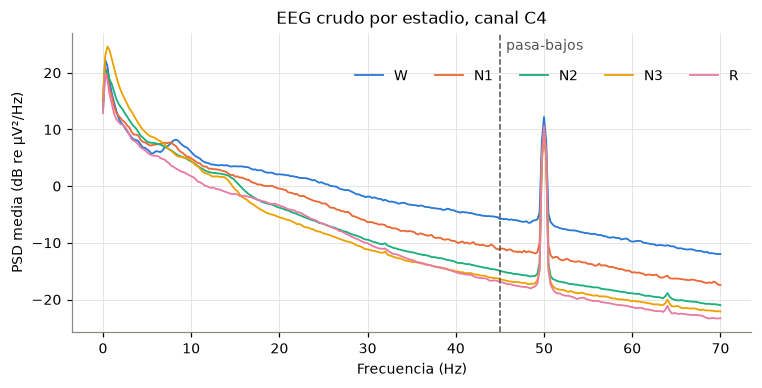

In [5]:
acumulado = {e: [] for e in COLOR_ESTADIO}
for r in pacientes(N_DETALLE):
    f, por_estadio = exploratorio.espectro_por_estadio(r, EEG_C4)
    for e, psd in por_estadio.items():
        acumulado[e].append(10 * np.log10(psd))

fig, ax = plt.subplots(figsize=(7, 3.6))
visibles = f <= 70
for e, color in COLOR_ESTADIO.items():
    ax.plot(f[visibles], np.mean(acumulado[e], axis=0)[visibles], c=color, label=NOMBRES_ESTADIOS[e])
ax.axvline(CFG.pasa_bajos_hz, c=GRIS, ls="--", lw=1)
ax.text(CFG.pasa_bajos_hz + 0.7, ax.get_ylim()[1] - 3, "pasa-bajos", color=GRIS)
ax.set(xlabel="Frecuencia (Hz)", ylabel="PSD media (dB re µV²/Hz)", title="EEG crudo por estadio, canal C4")
ax.legend(ncols=5, loc="upper right", bbox_to_anchor=(1, 0.92))
fig.tight_layout()
guardar(fig, "a_espectro_por_estadio")

El espectro cae de forma continua. W tiene más potencia que el resto en las frecuencias altas, lo que refleja actividad muscular.

Las bandas de los descriptores llegan hasta 30 Hz y la pendiente espectral se calcula entre 1 y 40 Hz. Por encima de 40 Hz la señal no aporta a ningún descriptor y lo que queda es sobre todo músculo y línea eléctrica. Por eso conviene un pasa-bajos algo por encima de 40 Hz. El corte exacto lo justificamos en la sección 2, con la atenuación del filtro.

### 1.4 Saturación

Como vimos en la sección 1.2, el EEG no puede superar ±800 µV. Si la señal real es más grande, el archivo guarda el valor del borde y la forma de onda se pierde. Para identificar estos puntos, contamos como saturada toda muestra con valor absoluto de 799 µV o más, apenas debajo del borde para no depender del redondeo.

En cada canal medimos dos cosas. La primera es el porcentaje de muestras saturadas en toda la noche. La segunda es el porcentaje de épocas de 30 s que tienen al menos una muestra saturada. La segunda importa más, porque los descriptores se calculan por época y una muestra en el borde indica que en esa época hubo un artefacto de más de 800 µV, mucho más grande que cualquier onda cerebral, que domina su espectro.

De cada paciente tomamos el canal más afectado y después resumimos entre pacientes.

In [6]:
por_paciente = crudo.groupby("paciente")[["muestras saturadas (%)", "épocas con saturación (%)"]].max()
display(por_paciente.describe().loc[["min", "50%", "75%", "max"]].round(3))
print("Pacientes con más saturación")
display(por_paciente.sort_values("épocas con saturación (%)", ascending=False).head(5).round(2))

,muestras saturadas (%),épocas con saturación (%)
min,0.000,0.113
50%,0.049,2.573
75%,0.106,4.899
max,2.232,37.447


Pacientes con más saturación


,muestras saturadas (%),épocas con saturación (%)
paciente,,
SN020,2.23,37.45
SN123,0.45,8.95
SN048,0.03,8.20
SN097,0.22,7.62
SN035,0.17,6.73


En el paciente mediano el 0,05 % de las muestras está saturado y el 2,6 % de las épocas tiene al menos una muestra saturada. Los dos números son distintos porque las saturaciones son tramos cortos. Ocupan poco tiempo en total pero aparecen en muchas épocas distintas, y cada una de esas épocas queda afectada.

El peor caso es SN020, con 37 % de épocas afectadas.

**Decisión.** No descartamos épocas, porque hay que clasificarlas todas. Los tramos que superan 500 µV quedan afuera del ajuste del filtro ocular y cardíaco, para que un artefacto no desajuste esos métodos.

### 1.5 Contaminación ocular

Calculamos la correlación entre cada canal de EEG y la diferencia E1 − E2 (las frontales, que suelen estar relacionadas a movimientos oculares), por estadio, y tomamos la mediana de 12 pacientes. Usamos el valor absoluto porque el signo cambia de un paciente a otro.

In [7]:
filas = []
for r in pacientes(N_DETALLE):
    for nombre, estadio in (("Toda la noche", None), ("W", W), ("N2", N2), ("N3", N3), ("REM", R)):
        if estadio is not None and not (r.estadios == estadio).any():
            continue
        for canal, valor in exploratorio.correlacion_eeg_eog(r, estadio).items():
            filas.append({"estadio": nombre, "canal": corto(canal), "correlación": abs(valor)})
fuga = pd.DataFrame(filas).pivot_table(index="estadio", columns="canal", values="correlación", aggfunc="median")
fuga.loc[["Toda la noche", "W", "REM", "N2", "N3"]].round(2)

canal,C3,C4,F4,O2
estadio,,,,
Toda la noche,0.07,0.11,0.17,0.09
W,0.06,0.11,0.13,0.05
REM,0.08,0.17,0.30,0.17
N2,0.10,0.23,0.26,0.21
N3,0.10,0.27,0.32,0.25


F4, el canal más cercano a los ojos, es el más contaminado en promedio de toda la noche. Nos llamó la atención que la correlación más alta aparece en N3, con 0,32, cuando en ese estadio casi no hay movimientos oculares según la bibliografía. Esto nos indica que E1 − E2 también está registrando ondas lentas cerebrales, que sabemos que están presentens en N3. Si corrigiéramos toda la noche con esa referencia podríamos borrar ondas reales, y por eso lo medimos más adelante, en la sección 3.

## 2. Filtrado

El EEG y el EOG llevan pasa-altos, pasa-bajos y notch. El EMG lleva un pasa-altos de 10 Hz, como recomienda la AASM, y el notch, pero no pasa-bajos porque su información está en las frecuencias altas. El ECG no se filtra acá porque Pan-Tompkins tiene su propio filtro.

Comparamos un diseño IIR Butterworth con uno FIR por ventana de Hamming. Las curvas muestran una sola pasada de cada filtro.

,Pasa-altos,Pasa-bajos,Notch,Tiempo en una noche (s)
IIR,orden 4,orden 4,orden 2,0.36
FIR,4225 coeficientes,423 coeficientes,423 coeficientes,0.61


Diferencia RMS entre IIR y FIR sobre EEG real 3.8 %


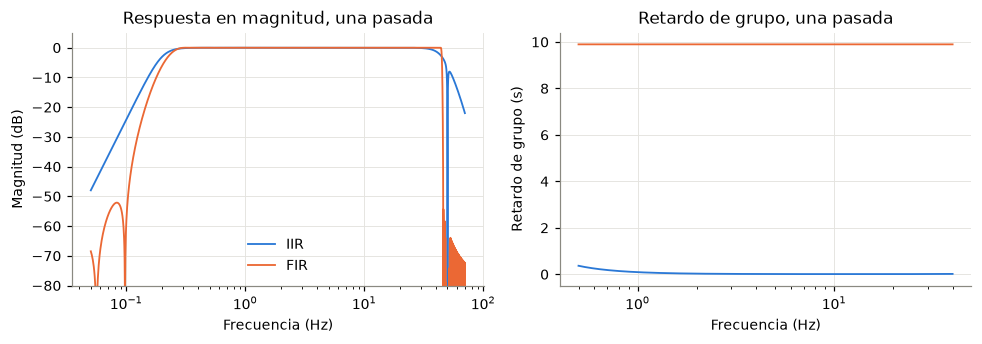

In [8]:
fs = 256.0
disenos = {"IIR": replace(CFG, tipo_filtro="iir"), "FIR": replace(CFG, tipo_filtro="fir")}
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for (nombre, c), color in zip(disenos.items(), (AZUL, NARANJA)):
    fr, magnitud, retardo = filtrado.respuesta_en_frecuencia(fs, c)
    util = (fr >= 0.05) & (fr <= 70)
    axs[0].semilogx(fr[util], 20 * np.log10(np.maximum(magnitud[util], 1e-6)), c=color, label=nombre)
    banda = (fr >= 0.5) & (fr <= 40)
    axs[1].semilogx(fr[banda], retardo[banda], c=color, label=nombre)
axs[0].set(ylim=(-80, 5), xlabel="Frecuencia (Hz)", ylabel="Magnitud (dB)", title="Respuesta en magnitud, una pasada")
axs[1].set(xlabel="Frecuencia (Hz)", ylabel="Retardo de grupo (s)", title="Retardo de grupo, una pasada")
axs[0].legend()
fig.tight_layout()
guardar(fig, "a_respuesta_filtros")

iir = filtrado.disenar_iir(fs, CFG.pasa_altos_hz, CFG.pasa_bajos_hz, CFG.notch_hz)
fir = filtrado.disenar_fir(fs, CFG.pasa_altos_hz, CFG.pasa_bajos_hz, CFG.notch_hz)
r = ejemplo()
tiempos = {}
salidas = {}
for nombre, tipo in (("IIR", "iir"), ("FIR", "fir")):
    inicio = time.perf_counter()
    salidas[nombre] = filtrado.filtrar_senal(r.senales[EEG_F4], r.fs, CFG.pasa_altos_hz, CFG.pasa_bajos_hz, CFG.notch_hz, tipo)
    tiempos[nombre] = time.perf_counter() - inicio
sana = np.abs(r.senales[EEG_F4]) < 500
display(pd.DataFrame({
    "Pasa-altos": [f"orden {2 * iir[0].shape[0]}", f"{len(fir[0])} coeficientes"],
    "Pasa-bajos": [f"orden {2 * iir[1].shape[0]}", f"{len(fir[1])} coeficientes"],
    "Notch": ["orden 2", f"{len(fir[2])} coeficientes"],
    "Tiempo en una noche (s)": [round(tiempos["IIR"], 2), round(tiempos["FIR"], 2)],
}, index=["IIR", "FIR"]))
print(f"Diferencia RMS entre IIR y FIR sobre EEG real {100 * np.std((salidas['IIR'] - salidas['FIR'])[sana]) / np.std(salidas['IIR'][sana]):.1f} %")

**Decisión.** Usamos el IIR aplicado hacia adelante y hacia atrás. Una sola pasada del IIR tiene retardo variable justo en las frecuencias bajas, y aplicarlo dos veces lo cancela. El FIR no tiene ese problema, pero su pasa-altos necesita 4225 coeficientes contra un orden 4.

### Atenuación del pasa-bajos y del notch

El pasa-bajos va en 45 Hz, entre el extremo de la pendiente espectral en 40 Hz y la línea eléctrica en 50 Hz. Pero un filtro no corta de golpe, así que medimos cuánto atenúa cada uno en las frecuencias que nos importan, aplicado ida y vuelta como en el procesamiento. En la tabla −100 dB significa que la componente se elimina por completo.

In [9]:
frecuencias = [30, 35, 40, 45, 49, 50, 51, 55, 60]


def atenuacion_ida_y_vuelta(**cambios):
    # Aplicar el filtro hacia adelante y hacia atrás duplica la atenuación en dB.
    fr, magnitud, _ = filtrado.respuesta_en_frecuencia(fs, replace(CFG, tipo_filtro="iir", **cambios))
    db = 2 * 20 * np.log10(np.maximum(magnitud, 1e-10))
    return [max(float(db[np.argmin(np.abs(fr - x))]), -100.0) for x in frecuencias]


pd.DataFrame({
    "Pasa-bajos": atenuacion_ida_y_vuelta(pasa_altos_hz=None, notch_hz=None),
    "Notch": atenuacion_ida_y_vuelta(pasa_altos_hz=None, pasa_bajos_hz=None),
    "Cadena completa": atenuacion_ida_y_vuelta(),
    "Pasa-bajos en 50 Hz": atenuacion_ida_y_vuelta(pasa_altos_hz=None, notch_hz=None, pasa_bajos_hz=50.0),
}, index=[f"{x} Hz" for x in frecuencias]).round(1)

,Pasa-bajos,Notch,Cadena completa,Pasa-bajos en 50 Hz
30 Hz,-0.2,-0.0,-0.2,-0.1
35 Hz,-0.8,-0.0,-0.8,-0.3
40 Hz,-2.4,-0.1,-2.5,-0.9
45 Hz,-6.0,-0.2,-6.2,-2.6
49 Hz,-10.5,-4.5,-15.1,-5.2
50 Hz,-11.8,-100.0,-100.0,-6.0
51 Hz,-13.2,-4.6,-17.8,-7.0
55 Hz,-19.2,-0.2,-19.4,-11.6
60 Hz,-27.2,-0.1,-27.3,-18.6


El pasa-bajos solo atenúa 11,8 dB en 50 Hz, poco frente a picos de línea que llegan a 54 dB. La línea la elimina el notch. En 50 Hz la quita por completo y a 1 Hz de distancia todavía atenúa 4,5 dB, lo que alcanza porque el pico de la línea es muy angosto. El pasa-bajos cumple otra función, que es sacar lo que está por encima de la banda útil, sobre todo actividad muscular.

En 30 Hz, donde terminan las bandas, atenúa solo 0,2 dB. En 40 Hz atenúa 2,4 dB, y ahí termina el rango de la pendiente espectral. Como el pasa-bajos no hace falta para la línea, podríamos subirlo a 50 Hz y en 40 Hz atenuaría 0,9 dB. Bajarlo a 40 Hz, en cambio, atenuaría 6 dB justo en ese borde.

### ¿Conviene subir el pasa-bajos a 50 Hz?

El argumento a favor de 50 Hz es razonable, así que medimos si cambia algo. Filtramos 12 pacientes con el pasa-bajos en 45 y en 50 Hz y comparamos los descriptores que pasan por este filtro y usan las reglas. La delta relativa se mide en F4 y la alfa relativa en O2, los canales de las reglas de N3 y de vigilia. La energía del EOG pasa por el mismo pasa-bajos que el EEG. Agregamos la pendiente espectral en F4, que es la que llega hasta 40 Hz.

In [10]:
filas = []
for r in pacientes(N_DETALLE):
    medidas = {}
    for corte in (45.0, 50.0):
        s = filtrado.filtrar_registro(r, replace(CFG, pasa_bajos_hz=corte)).senales
        f, psd_f4 = espectro.psd_welch(segmentar(s[EEG_F4], r.fs, r.n_epocas), r.fs)
        _, psd_o2 = espectro.psd_welch(segmentar(s[EEG_O2], r.fs, r.n_epocas), r.fs)
        rango = (f >= 1) & (f <= 40)

        def relativa(psd, banda):
            potencias = espectro.potencia_bandas(f, psd, {"banda": banda, "total": (0.5, 30)})
            return potencias["banda"] / potencias["total"]

        medidas[corte] = {
            "pendiente": espectro.pendiente_espectral(f[rango], psd_f4[:, rango]),
            "Delta relativa en F4": relativa(psd_f4, (0.5, 4)),
            "Alfa relativa en O2": relativa(psd_o2, (8, 13)),
            "Energía del EOG": (segmentar(s[EOG_E1] - s[EOG_E2], r.fs, r.n_epocas) ** 2).mean(axis=1),
        }
    a, b = medidas[45.0], medidas[50.0]
    cambio = b["pendiente"] - a["pendiente"]
    filas.append({
        "Pendiente en F4, cambio medio": float(cambio.mean()),
        "Pendiente en F4, desvío del cambio entre épocas": float(cambio.std()),
        "Pendiente en F4, dispersión entre épocas": float(a["pendiente"].std()),
        **{f"{k}, cambio (%)": 100 * float(np.median(np.abs(b[k] - a[k]) / a[k]))
           for k in ("Delta relativa en F4", "Alfa relativa en O2", "Energía del EOG")},
    })
pd.DataFrame(filas).median().round(4).to_frame("Mediana de 12 pacientes")

,Mediana de 12 pacientes
"Pendiente en F4, cambio medio",0.0476
"Pendiente en F4, desvío del cambio entre épocas",0.0000
"Pendiente en F4, dispersión entre épocas",0.6190
"Delta relativa en F4, cambio (%)",0.0140
"Alfa relativa en O2, cambio (%)",0.0211
"Energía del EOG, cambio (%)",0.1009


La pendiente cambia 0,048 en todas las épocas por igual, y el desvío de ese cambio es cero. Pasa porque el filtro multiplica el espectro de todas las épocas por la misma curva, y en escala logarítmica eso suma lo mismo a cada una. El corrimiento es el 8 % de la dispersión de la pendiente entre épocas, pero no cambia el orden de las épocas dentro de una noche, que es lo que miran las reglas al usar percentiles. Además las reglas no usan la pendiente. La delta relativa, la alfa relativa y la energía del EOG cambian un 0,1 % o menos.

**Decisión.** Mantenemos el pasa-bajos en 45 Hz. Con 50 Hz los descriptores que usan las reglas quedarían iguales, así que los dos cortes son válidos. Elegimos 45 Hz porque queda más cerca de los 35 Hz que recomienda la AASM para el EEG y porque cambiarlo obligaría a recalcular todos los descriptores sin ganar nada.

### Efecto sobre una onda lenta

Pasamos una onda de forma conocida, con pico de −80 µV, por cada variante. Así vemos qué le hace cada filtro a la forma de las ondas de N3.

,Pico negativo (µV),Corrimiento del pico (ms),Error RMS (%)
"IIR 0,2 Hz, una pasada",-53.8,-78.1,88.0
"IIR 0,2 Hz, ida y vuelta",-71.8,0.0,27.4
"FIR 0,2 Hz",-72.0,0.0,27.1
"IIR 0,5 Hz, ida y vuelta",-56.8,0.0,48.3


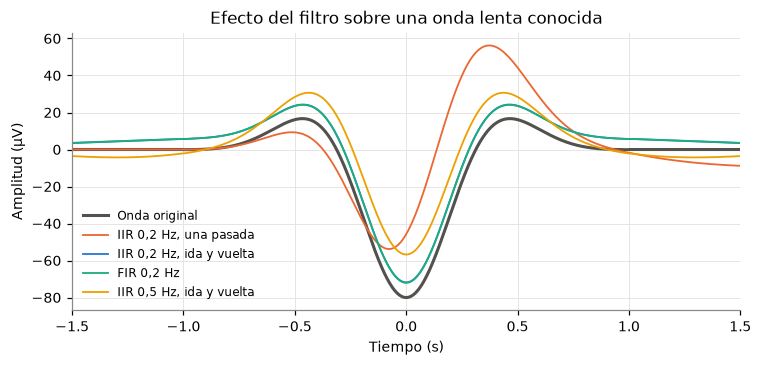

In [11]:
onda = hipotesis.onda_lenta_modelo(fs)
x = np.zeros(int(60 * fs))
centro = int(30 * fs)
inicio = centro - len(onda) // 2
x[inicio : inicio + len(onda)] = onda
t = (np.arange(len(x)) - centro) / fs

sos_pa = filtrado.disenar_iir(fs, CFG.pasa_altos_hz, None, None)[0]
variantes = {
    "IIR 0,2 Hz, una pasada": signal.sosfilt(sos_pa, x),
    "IIR 0,2 Hz, ida y vuelta": filtrado.filtrar_senal(x, fs, 0.2, 45.0, None, "iir"),
    "FIR 0,2 Hz": filtrado.filtrar_senal(x, fs, 0.2, 45.0, None, "fir"),
    "IIR 0,5 Hz, ida y vuelta": filtrado.filtrar_senal(x, fs, 0.5, 45.0, None, "iir"),
}
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(t, x, c=GRIS, lw=2, label="Onda original")
for (nombre, y), color in zip(variantes.items(), (NARANJA, AZUL, AGUA, AMARILLO)):
    ax.plot(t, y, c=color, label=nombre)
ax.set(xlim=(-1.5, 1.5), xlabel="Tiempo (s)", ylabel="Amplitud (µV)", title="Efecto del filtro sobre una onda lenta conocida")
ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "a_filtro_onda_lenta")

pico_real = t[np.argmin(x)]
pd.DataFrame({
    nombre: {
        "Pico negativo (µV)": round(float(y.min()), 1),
        "Corrimiento del pico (ms)": round(1000 * float(t[np.argmin(y)] - pico_real), 1),
        "Error RMS (%)": round(100 * float(np.sqrt(np.mean((y - x) ** 2)) / np.sqrt(np.mean(x[x != 0] ** 2) * np.mean(x != 0))), 1),
    }
    for nombre, y in variantes.items()
}).T

Una sola pasada del IIR corre el pico 78 ms y lo achica a −54 µV. Aplicado ida y vuelta el corrimiento desaparece y el pico queda en −72 µV, igual que con el FIR.

Decidimos entonces bajar el pasa-altos desde 0,5 Hz que habíamos planteado inicialmente, hasta 0,2 Hz. Con 0,5 Hz la onda queda en −57 µV, por debajo del umbral de detección de −60 µV, y se perdería. Y nos quedamos con el filtro IIR pasado dos veces en vez del FIR por lo que vimos antes de que el segundo necesita muchos más parámetros, y tiene un tiempo de cómputo 0.56 s por noche contra 0.37 s del IIR.

### Verificación del notch

50.0   -7.3
60.0    0.3
Name: Prominencia tras filtrar (dB), dtype: float64

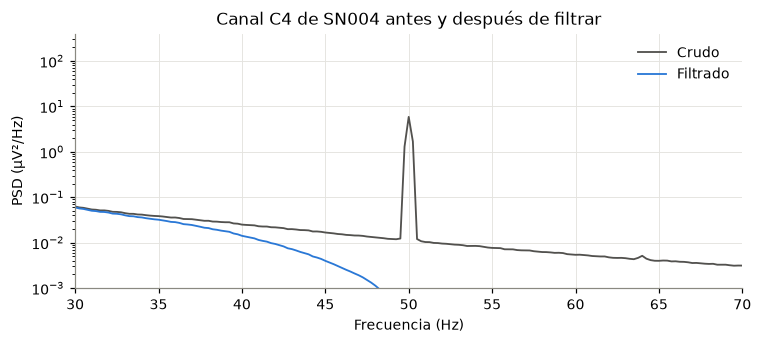

In [12]:
r = ejemplo()
limpio = filtrado.filtrar_registro(r, CFG)
f, antes = exploratorio.espectro_del_registro(r.senales[EEG_C4], r.fs)
_, despues = exploratorio.espectro_del_registro(limpio.senales[EEG_C4], r.fs)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(f, antes, c=GRIS, label="Crudo")
ax.semilogy(f, despues, c=AZUL, label="Filtrado")
ax.set(xlim=(30, 70), ylim=(1e-3, None), xlabel="Frecuencia (Hz)", ylabel="PSD (µV²/Hz)", title=f"Canal C4 de {r.id} antes y después de filtrar")
ax.legend()
fig.tight_layout()
guardar(fig, "a_notch")
pd.Series(exploratorio.prominencia_de_linea(f, despues), name="Prominencia tras filtrar (dB)").round(1)

El pico de 50 Hz desaparece y el espectro queda sin interferencia de línea en la banda que usamos.

## 3. Artefacto ocular

Entre la córnea y la retina hay una diferencia de potencial, con la córnea positiva. Cuando el ojo se mueve o parpadea, cambia el potencial que llega a los electrodos del cuero cabelludo, sobre todo a los frontales. En el EEG aparece como deflexiones lentas y grandes, en la misma banda que las ondas delta de 0,5 a 4 Hz. Por eso se puede confundir con las ondas lentas de N3.

### Cómo se quita

E1 y E2 están al costado de cada ojo. Cuando los ojos se mueven hacia un lado, uno sube y el otro baja, así que la diferencia E1 − E2 registra el movimiento con mucha amplitud. Usamos esa diferencia como referencia del artefacto.

Comparamos dos filtros, Wiener y NLMS. Wiener calcula un único grupo de pesos para toda la noche, resolviendo las ecuaciones de Wiener-Hopf. NLMS ajusta los pesos muestra a muestra y puede seguir cambios a lo largo de la noche.

El problema es que nuestra señal de referencia no registra solo los ojos. E1 y E2 también están cerca del cerebro y captan sus ondas lentas, como mostró la sección 1.5, donde la correlación entre EEG y EOG fue máxima en N3, el estadio con menos movimientos oculares. Si el filtro corrigiera toda la noche, restaría del EEG todo lo que se parece a la referencia, incluidas las ondas lentas reales de N3.

La solución es agregar una compuerta que hace que el filtro actúe solo cuando hay movimientos oculares. Para encontrarlos calculamos el valor eficaz de la referencia en ventanas de 2 s. Los movimientos oculares son mucho más grandes que la actividad cerebral que capta el EOG, así que consideramos que hay movimiento cuando ese valor supera el doble de su mediana de la noche.

La compuerta es una ganancia g entre 0 y 1 que multiplica la corrección. El EEG corregido es el EEG - g*artefacto estimado. Donde hay movimiento g vale 1 y se resta todo el artefacto. Donde no hay, g vale 0 y el EEG queda igual. Y en los bordes g pasa de 0 a 1 a lo largo de 2 s para no crear un escalón en la señal. Los pesos del filtro también se calculan solo con los tramos donde g vale 1, así describen cómo llega el movimiento ocular al EEG y no cómo llegan también las ondas lentas.

### Cómo evaluamos

Probamos cuatro variantes, Wiener y NLMS, cada uno aplicado en toda la noche con o sin compuerta, en 12 pacientes.

Lo medimos en F4 porque es el canal más cercano a los ojos y el más contaminado según la sección 1.5, así que es donde más se nota lo que hace la corrección. Y es el canal donde las reglas miden la potencia delta y cuentan las ondas lentas para reconocer N3, siguiendo la AASM, que usa una derivación frontal para las ondas lentas.

Por otro lado, medimos la potencia delta y las ondas lentas detectadas porque el artefacto ocular cae en la misma banda que las ondas lentas, y esos son los dos descriptores con los que las reglas reconocen N3. Los separamos por estadio porque cada uno muestra algo distinto: en W y REM hay muchos movimientos oculares y casi no hay ondas lentas reales, así que una buena corrección debería bajar la delta y las ondas detectadas. En N3 casi no hay movimientos y sí muchas ondas lentas reales, así que una buena corrección no debería cambiar nada. Si en N3 bajan, el filtro está borrando actividad cerebral.

Fracción de cada estadio en la que actúa la compuerta


,W,N1,N2,N3,REM
Fracción activa,0.37,0.21,0.05,0.04,0.3


Cambio de potencia delta en F4 (dB)


,W,N1,N2,N3,REM
variante,,,,,
Wiener en toda la noche,-0.18,-0.15,-0.15,-0.24,-0.87
NLMS en toda la noche,0.41,0.76,-0.15,-0.45,0.38
Wiener con compuerta,-0.15,-0.06,-0.01,-0.02,-0.85
NLMS con compuerta,0.37,0.70,0.05,0.07,0.00


Ondas lentas detectadas en F4, sumando los pacientes


,W,N1,N2,N3,REM
variante,,,,,
Sin corrección,7957,1276,4052,5018,831
Wiener en toda la noche,7897,1280,3962,4692,675
NLMS en toda la noche,8213,1340,3917,4334,812
Wiener con compuerta,7852,1296,4033,4994,675
NLMS con compuerta,8109,1352,4079,4943,762


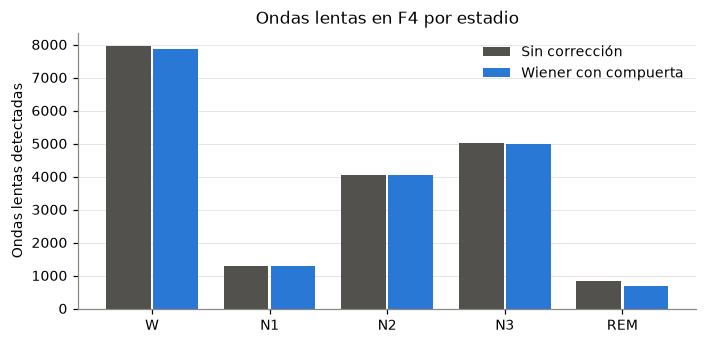

In [13]:
SOS_DELTA = signal.butter(2, (0.5, 4), "bandpass", fs=256.0, output="sos")
ESTADIOS_TABLA = {"W": W, "N1": N1, "N2": N2, "N3": N3, "REM": R}
VARIANTES = {
    "Wiener en toda la noche": replace(CFG, metodo_ocular="wiener", ocular_umbral_relativo=0.0),
    "NLMS en toda la noche": replace(CFG, metodo_ocular="nlms", ocular_umbral_relativo=0.0),
    "Wiener con compuerta": replace(CFG, metodo_ocular="wiener"),
    "NLMS con compuerta": replace(CFG, metodo_ocular="nlms"),
}


def ondas_por_estadio(senal, r):
    picos = ondas_lentas.detectar_ondas_lentas(senal, r.fs, (0.2, 4.0), -60.0, 75.0)
    epocas = picos // int(30 * r.fs)
    estadios = r.estadios[epocas[epocas < r.n_epocas]]
    return {n: int((estadios == e).sum()) for n, e in ESTADIOS_TABLA.items()}


def potencia_delta(senal, r):
    epocas = segmentar(signal.sosfiltfilt(SOS_DELTA, senal), r.fs, r.n_epocas)
    return {n: float((epocas[r.estadios == e] ** 2).mean()) for n, e in ESTADIOS_TABLA.items() if (r.estadios == e).any()}


filas, conteos, compuerta = [], [], []
for r in pacientes(N_DETALLE):
    base = filtrado.filtrar_registro(r, CFG)
    ref = base.senales[EOG_E1] - base.senales[EOG_E2]
    g = segmentar(ocular.actividad_ocular(ref, r.fs, CFG), r.fs, r.n_epocas).mean(axis=1)
    compuerta.append({n: float(g[r.estadios == e].mean()) for n, e in ESTADIOS_TABLA.items() if (r.estadios == e).any()})
    delta_0 = potencia_delta(base.senales[EEG_F4], r)
    conteos.append({"variante": "Sin corrección", **ondas_por_estadio(base.senales[EEG_F4], r)})
    for nombre, c in VARIANTES.items():
        s = ocular.remover_artefacto_ocular(base, c).senales[EEG_F4]
        delta = potencia_delta(s, r)
        filas.append({"variante": nombre, **{e: 10 * np.log10(delta[e] / delta_0[e]) for e in delta}})
        conteos.append({"variante": nombre, **ondas_por_estadio(s, r)})

print("Fracción de cada estadio en la que actúa la compuerta")
display(pd.DataFrame(compuerta).mean().round(2).to_frame("Fracción activa").T)
print("Cambio de potencia delta en F4 (dB)")
display(pd.DataFrame(filas).groupby("variante")[list(ESTADIOS_TABLA)].mean().loc[list(VARIANTES)].round(2))
print("Ondas lentas detectadas en F4, sumando los pacientes")
total = pd.DataFrame(conteos).groupby("variante").sum().loc[["Sin corrección", *VARIANTES]]
display(total)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
posiciones = np.arange(len(ESTADIOS_TABLA))
ax.bar(posiciones - 0.2, total.loc["Sin corrección"], 0.38, color=GRIS, label="Sin corrección")
ax.bar(posiciones + 0.2, total.loc["Wiener con compuerta"], 0.38, color=AZUL, label="Wiener con compuerta")
ax.set_xticks(posiciones, list(ESTADIOS_TABLA))
ax.grid(axis="x", visible=False)
ax.set(ylabel="Ondas lentas detectadas", title="Ondas lentas en F4 por estadio")
ax.legend()
fig.tight_layout()
guardar(fig, "a_ondas_por_estadio")

La compuerta actúa en el 37 % de W y el 30 % de REM, y solo en el 4 % de N3, lo que coincide con los estadios donde hay movimientos oculares.

Corrigiendo toda la noche se pierden ondas de N3, un 6,5 % con Wiener y un 14 % con NLMS. Con la compuerta, Wiener deja N3 prácticamente igual, de 5018 a 4994 ondas y −0,02 dB de potencia delta. Además baja un 19 % las ondas detectadas en REM, de 831 a 675. Ese estadio casi no tiene ondas lentas reales, así que las que desaparecen eran movimientos oculares.

NLMS con compuerta no reduce delta en REM y la aumenta en W y N1, cuando debería bajarla.

**Decisión.** Usamos Wiener con compuerta, y eventualmente usamos NLMS para comparar resultados.

### Ejemplo en una época de REM

Elegimos la época de REM con más movimientos oculares del paciente de ejemplo.

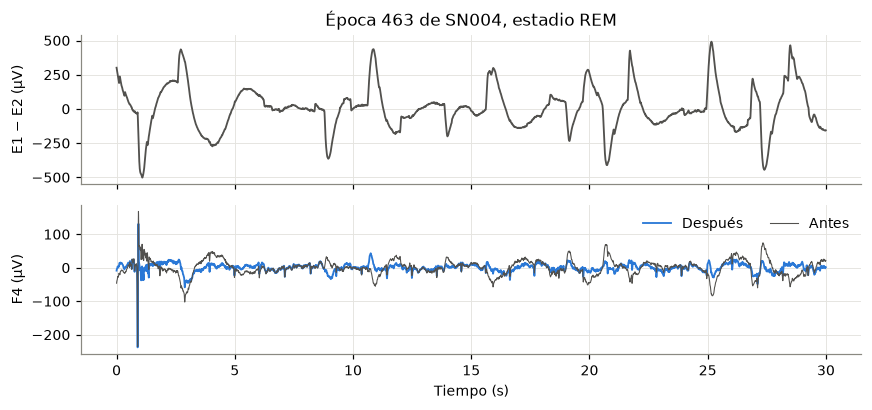

In [14]:
r = ejemplo()
base = filtrado.filtrar_registro(r, CFG)
limpio = ocular.remover_artefacto_ocular(base, CFG)
ref = base.senales[EOG_E1] - base.senales[EOG_E2]
epocas_ref = segmentar(ref, r.fs, r.n_epocas)
candidatas = np.flatnonzero(r.estadios == R) if (r.estadios == R).any() else np.arange(r.n_epocas)
epoca = candidatas[np.argmax((epocas_ref[candidatas] ** 2).mean(axis=1))]
n = int(30 * r.fs)
t = np.arange(n) / r.fs
tramo = slice(epoca * n, (epoca + 1) * n)
fig, axs = plt.subplots(2, 1, figsize=(8, 3.8), sharex=True)
axs[0].plot(t, ref[tramo], c=GRIS)
axs[0].set(ylabel="E1 − E2 (µV)", title=f"Época {epoca} de {r.id}, estadio REM")
axs[1].plot(t, limpio.senales[EEG_F4][tramo], c=AZUL, label="Después")
axs[1].plot(t, base.senales[EEG_F4][tramo], c=GRIS, lw=0.7, label="Antes")
axs[1].set(xlabel="Tiempo (s)", ylabel="F4 (µV)")
axs[1].legend(ncols=2)
fig.tight_layout()
guardar(fig, "a_ocular_ejemplo")

Después de la corrección el EEG sigue menos a los movimientos oculares. La espiga cerca del primer segundo ya está en la señal original, así que no la genera el filtro.

## 4. Latidos y artefacto cardíaco

### 4.1 Detección con Pan-Tompkins

Los latidos son necesarios para quitar el artefacto cardíaco del EEG y para la HRV. El algoritmo aplica un pasa-banda de 5 a 15 Hz, derivada, cuadrado e integración de 150 ms, y compara los picos con umbrales que se adaptan a lo largo de la noche.

Agregamos dos cosas para los datos reales. La polaridad se decide una vez por noche, para que el punto de referencia sea el mismo en todos los latidos. Y los umbrales se reinician si pasan 5 s sin latidos, para que un artefacto no los deje desajustados.

La tabla también muestra qué porcentaje de latidos descartamos por tener una forma distinta a la típica. Ese paso se explica en la subsección siguiente.

,latidos,RR mediano (s),latidos descartados (%),RR válidos (%)
paciente,,,,
SN001,37861,0.69,11.06,46.75
SN003,28403,1.04,6.81,91.78
SN004,29215,1.06,0.46,99.31
SN005,31124,1.02,11.40,80.05
SN008,24687,1.04,0.90,98.28
SN009,29956,0.91,1.94,95.90
SN015,31871,0.82,0.99,98.06
SN020,34872,0.84,6.25,91.32
SN022,31798,0.98,4.47,94.59


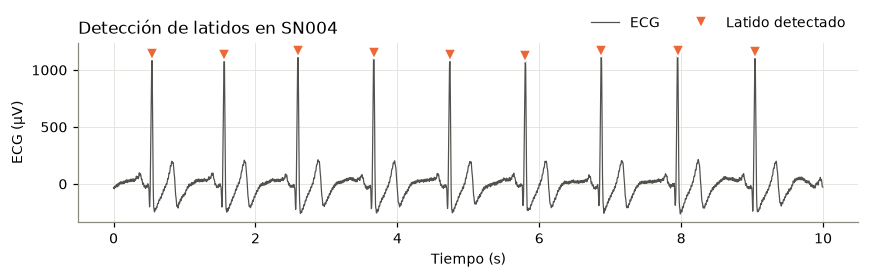

In [15]:
filas = []
for r in pacientes(N_DETALLE):
    latidos = qrs.detectar_latidos(r.senales[ECG], r.fs)
    conservados = hrv.descartar_ectopicos(r.senales[ECG], latidos, r.fs)
    t_rr, rr = hrv.intervalos_rr(latidos, r.fs)
    _, validos = hrv.filtrar_intervalos(*hrv.intervalos_rr(conservados, r.fs))
    filas.append({
        "paciente": r.id, "latidos": len(latidos), "RR mediano (s)": np.median(rr),
        "latidos descartados (%)": 100 * (1 - len(conservados) / len(latidos)),
        "RR válidos (%)": 100 * len(validos) / len(rr),
    })
display(pd.DataFrame(filas).set_index("paciente").round(2))

r = ejemplo()
latidos = qrs.detectar_latidos(r.senales[ECG], r.fs)
a = int(3600 * r.fs)
b = a + int(10 * r.fs)
m = (latidos >= a) & (latidos < b)
t = np.arange(a, b) / r.fs - a / r.fs
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(t, r.senales[ECG][a:b], c=GRIS, lw=0.8, label="ECG")
ax.plot((latidos[m] - a) / r.fs, r.senales[ECG][latidos[m]], ls="", marker="v", ms=8, mfc=NARANJA, mec="white", label="Latido detectado")
ax.set(xlabel="Tiempo (s)", ylabel="ECG (µV)")
ax.set_title(f"Detección de latidos en {r.id}", loc="left")
ax.legend(ncols=2, loc="lower right", bbox_to_anchor=(1, 1.0))
fig.tight_layout()
guardar(fig, "a_qrs")

Los RR medianos están en valores normales. En 10 de los 12 pacientes se conserva al menos el 90 % de los intervalos. SN001 es la excepción más marcada, con 47 %. Eso puede deberse a que el detector falla o a que el ritmo del paciente es irregular, así que lo revisamos más abajo.

### Descarte de latidos por forma

Para la HRV solo sirven los latidos normales, los que inicia el nodo sinusal, porque son los que reflejan cómo el sistema nervioso regula el ritmo. Un latido que nace en otro lugar del corazón deja intervalos que no tienen esa información. Para encontrarlos comparamos la forma de cada latido con la del latido típico de la noche.

El latido típico no lo elegimos a mano ni sale de los primeros latidos, sino que lo calculamos para cada paciente con todos los latidos de su noche, de la siguiente forma:

1. Filtramos el ECG entre 0,5 y 40 Hz para quitar la deriva de la línea de base y el ruido de alta frecuencia.
2. Recortamos una ventana de −0,2 a 0,4 s alrededor de cada onda R, que abarca la onda P, el QRS y buena parte de la onda T, y le restamos su media.
3. El latido típico lo calculamos como la mediana de todas esas ventanas. Usamos la mediana porque los latidos atípicos son la minoría y casi no la mueven, mientras que un promedio se deformaría con ellos.
4. Calculamos la correlación de cada ventana con el latido típico y conservamos los latidos con correlación de 0,8 o más (entre 0 y 1).

La correlación mide el parecido de forma sin importar la amplitud. Así, un latido más chico por la respiración o por un cambio de posición no se descarta.

En la siguiente figura se ven el latido típico de SN001 junto a 20 latidos conservados y 20 descartados, y la distribución de la correlación en los 12 pacientes.

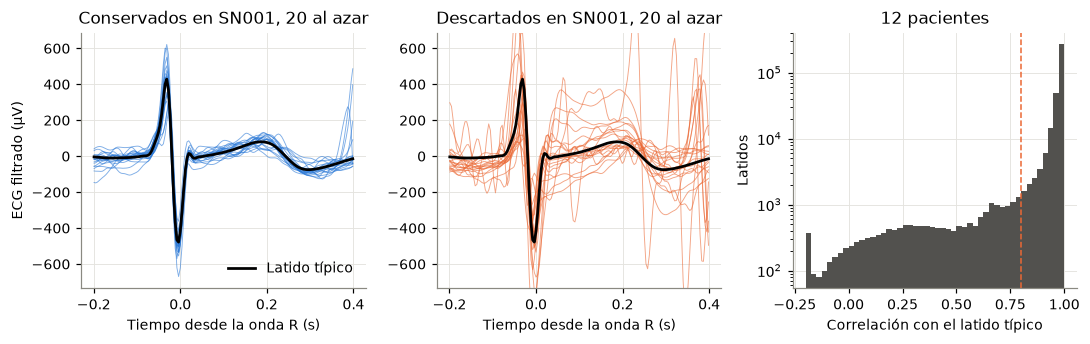

Umbral,0.7,0.8,0.9
Latidos descartados (%),4.0,5.2,7.8


Mediana de la correlación 0.987


In [16]:
correlaciones = []
for r in pacientes(N_DETALLE):
    latidos = qrs.detectar_latidos(r.senales[ECG], r.fs)
    tipico, ventanas, correlacion, _ = hrv.comparar_con_latido_tipico(r.senales[ECG], latidos, r.fs)
    correlaciones.append(correlacion)
    if r.id == "SN001" or "SN001" not in IDS:
        ejemplo_forma = (r.id, tipico, ventanas, correlacion, r.fs)
todas = np.concatenate(correlaciones)

id_forma, tipico, ventanas, correlacion, fs_ecg = ejemplo_forma
t = (np.arange(len(tipico)) + round(hrv.VENTANA_LATIDO_S[0] * fs_ecg)) / fs_ecg
azar = np.random.default_rng(0)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, elegidos, color, titulo in (
    (axs[0], correlacion >= hrv.UMBRAL_FORMA, AZUL, "Conservados"),
    (axs[1], correlacion < hrv.UMBRAL_FORMA, NARANJA, "Descartados"),
):
    for v in ventanas[azar.choice(np.flatnonzero(elegidos), 20, replace=False)]:
        ax.plot(t, v, c=color, lw=0.6, alpha=0.6)
    ax.plot(t, tipico, c="black", lw=1.8, label="Latido típico")
    ax.set(xlabel="Tiempo desde la onda R (s)", title=f"{titulo} en {id_forma}, 20 al azar")
axs[0].set(ylabel="ECG filtrado (µV)")
axs[0].legend(loc="lower right")
axs[1].set_ylim(axs[0].get_ylim())
axs[2].hist(np.clip(todas, -0.2, 1), bins=np.arange(-0.2, 1.0001, 0.025), color=GRIS)
axs[2].axvline(hrv.UMBRAL_FORMA, c=NARANJA, ls="--", lw=1)
axs[2].set(yscale="log", xlabel="Correlación con el latido típico", ylabel="Latidos", title=f"{len(correlaciones)} pacientes")
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Latidos descartados (%)": {u: 100 * np.mean(todas < u) for u in (0.7, 0.8, 0.9)},
}).rename_axis("Umbral").round(1).T)
print(f"Mediana de la correlación {np.median(todas):.3f}")

Los latidos conservados se superponen con el típico y solo cambian un poco en amplitud. Entre los descartados hay de tres tipos. Algunos tienen otra forma desde el comienzo, otros tienen ruido encima, y otros empiezan igual que el típico pero el latido siguiente llega antes de 0,4 s y entra en la ventana. Esto último pasa con los latidos prematuros, y esos intervalos tan cortos los quitaría igual el filtro de intervalos de la sección 6.

Para ver si el umbral de 0,8 está bien ubicado, analizamos la correlación global de los 12 pacientes. En los 12 pacientes la mediana de la correlación es 0,987. La mayoría de los latidos se concentra cerca de 1 y el resto forma una cola casi plana entre 0 y 0,75. No hay un valle que marque un umbral exacto, y el 0,8 queda donde empieza a subir el pico de los latidos normales. Moverlo entre 0,7 y 0,9 hace variar los latidos descartados entre 4,0 % y 7,8 %.

**Decisión.** Usamos 0,8. Nos pareció que un umbral más alto descartaría latidos normales con algo de ruido, cuyo instante sigue siendo correcto, y uno más bajo dejaría pasar latidos de otra forma.

### Revisión del ECG de SN001

Graficamos tres tramos de 12 s de su ECG con los latidos detectados. El primero es un tramo regular y los otros dos son irregulares. También contamos cuántos intervalos son más de un 20 % más cortos que la mediana de sus vecinos, que es lo que deja un latido que llega antes de tiempo.

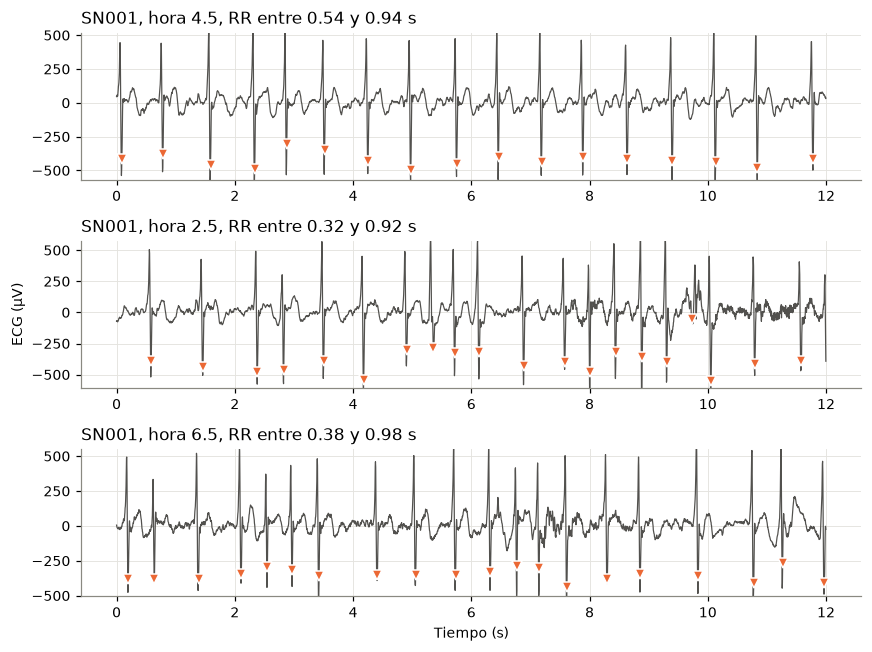

Intervalos más de un 20 % más cortos que la mediana local en SN001 24 %
Lo mismo en los otros 11 pacientes, mediana 1.8 % y máximo 7.2 %


In [17]:
if "SN001" in IDS:
    r = cargar_registro("SN001")
    latidos = qrs.detectar_latidos(r.senales[ECG], r.fs)
    fig, axs = plt.subplots(3, 1, figsize=(8, 6))
    for ax, hora in zip(axs, (4.5, 2.5, 6.5)):
        a = int(hora * 3600 * r.fs)
        b = a + int(12 * r.fs)
        m = (latidos >= a) & (latidos < b)
        ax.plot(np.arange(a, b) / r.fs - a / r.fs, r.senales[ECG][a:b], c=GRIS, lw=0.8)
        ax.plot((latidos[m] - a) / r.fs, r.senales[ECG][latidos[m]], ls="", marker="v", ms=7, mfc=NARANJA, mec="white")
        ax.set_ylim(np.percentile(r.senales[ECG][a:b], [0.2, 99.8]))
        rr = np.diff(latidos[m]) / r.fs
        ax.set_title(f"SN001, hora {hora}, RR entre {rr.min():.2f} y {rr.max():.2f} s", loc="left")
    axs[1].set(ylabel="ECG (µV)")
    axs[-1].set(xlabel="Tiempo (s)")
    fig.tight_layout()

    plt.show()

    # Un latido que llega antes de tiempo deja un intervalo mucho más corto que sus vecinos.
    cortos = {}
    for r in pacientes(N_DETALLE):
        _, rr = hrv.intervalos_rr(qrs.detectar_latidos(r.senales[ECG], r.fs), r.fs)
        mediana_local = ndimage.median_filter(rr, size=hrv.MUESTRAS_MEDIANA_RR, mode="nearest")
        cortos[r.id] = 100 * np.mean(rr < 0.8 * mediana_local)
    cortos = pd.Series(cortos)
    print(f"Intervalos más de un 20 % más cortos que la mediana local en SN001 {cortos['SN001']:.0f} %")
    print(f"Lo mismo en los otros {len(cortos) - 1} pacientes, mediana {cortos.drop('SN001').median():.1f} % y máximo {cortos.drop('SN001').max():.1f} %")

Casi todas las marcas caen sobre un QRS claro y no quedan latidos sin marcar. El primer tramo es bastante regular, con RR entre 0,54 y 0,94 s. En los otros dos aparecen latidos que llegan antes de tiempo, con RR de 0,32 a 0,45 s entre otros de 0,7 a 0,9 s. Son QRS reales y no errores del detector, aunque varios tienen una forma algo distinta a la del latido típico.

Esto se repite en toda la noche. En SN001 el 24 % de los intervalos es más de un 20 % más corto que el de sus vecinos. En los otros 11 pacientes la mediana es 1,8 % y el máximo 7,2 %.

Hay alguna marca dudosa, como la de 9,7 s en el segundo tramo, que cae sobre una deflexión con ruido. Ese latido no llega a la HRV, porque su correlación con el latido típico es de 0,20 y el descarte por forma lo saca. En SN001 ese paso saca el 11 % de los latidos, entre ellos varios de los prematuros.

Por eso SN001 conserva menos intervalos. El problema está en su ritmo cardíaco y no en el detector, y su HRV es poco confiable.

### 4.2 Remoción del artefacto cardíaco

La cátedra nos sugirió comprobar si este artefacto es lo bastante grande como para que valga la pena removerlo.

Usamos un promedio sincronizado con los latidos. Para cada onda R que detectó Pan-Tompkins recortamos el EEG entre −0,2 y 0,6 s alrededor de ella y promediamos todas las ventanas de la noche. La actividad cerebral no tiene relación con el momento del latido, así que en unas ventanas suma y en otras resta, y su promedio tiende a cero. El artefacto, en cambio, aparece siempre en el mismo instante respecto de la R y sobrevive al promedio.

Como control repetimos el mismo promedio en instantes elegidos al azar, con la misma cantidad de ventanas. Ahí no hay nada sincronizado, así que lo que queda es el EEG que no alcanzó a cancelarse. Ese es el piso del método, y el artefacto solo es real si lo supera con claridad.

**Cómo lo removemos.** En cada latido restamos una plantilla, que es el promedio de las ventanas de los 30 latidos anteriores. La plantilla se va actualizando porque la forma del artefacto cambia a lo largo de la noche. Las ventanas con más de 500 µV pico a pico, que suelen ser movimientos, no entran en la plantilla.

Medimos la amplitud pico a pico del promedio antes y después de la remoción, y la del control al azar. También medimos cuánto cambia la potencia de cada banda al remover el artefacto, en toda la noche y en cada estadio. Si hay un cambio negativo implica que es potencia que se fue junto con el artefacto.

Amplitud pico a pico del promedio alrededor de los latidos (µV), mediana de los pacientes


,antes,después,al azar
canal,,,
F4,16.91,1.59,0.42
C4,14.26,1.81,0.46
O2,12.94,1.59,0.50
C3,8.38,0.94,0.39


Amplitud pico a pico en F4 por paciente (µV)


paciente,SN001,SN003,SN004,SN005,SN008,SN009,SN015,SN020,SN022,SN023,SN026,SN027
antes,13.51,19.30,26.78,13.22,25.87,3.96,25.30,5.09,14.51,31.53,23.27,13.64
después,2.84,1.83,2.86,0.98,3.91,0.68,1.35,3.44,0.58,3.69,1.32,0.96
al azar,0.39,0.75,0.19,0.51,0.36,0.57,0.26,2.52,0.65,0.39,0.42,0.42


Cambio de potencia al remover el artefacto (dB), mediana de los pacientes


banda,delta,theta,alfa,sigma,beta
canal,,,,,
F4,0.05,-0.27,-0.22,-0.39,-0.17
C4,0.04,-0.27,-0.15,-0.25,-0.14
O2,0.04,-0.16,-0.17,-0.29,-0.19
C3,0.08,0.06,0.01,-0.03,0.02


Cambio (dB) en las bandas que usan las reglas, por estadio


estadio,W,N1,N2,N3,REM
delta en F4,0.07,-0.01,0.03,0.07,-0.01
alfa en O2,-0.06,-0.12,-0.29,-0.45,-0.55
sigma en C4,-0.16,-0.21,-0.22,-0.39,-0.62


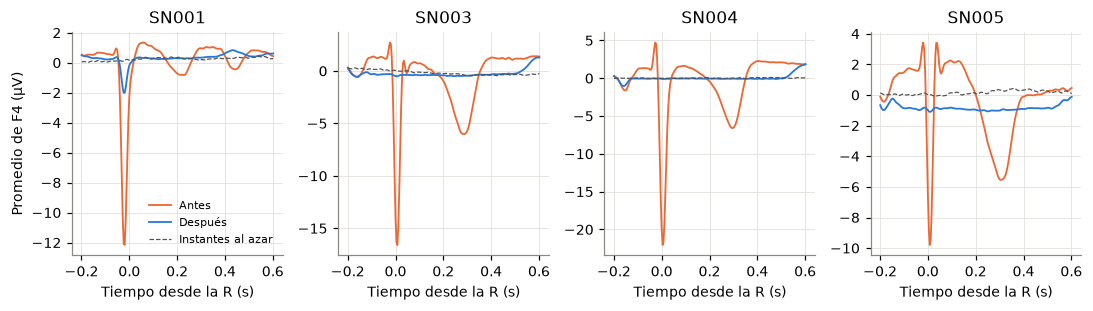

In [18]:
BANDAS = {"delta": (0.5, 4), "theta": (4, 8), "alfa": (8, 13), "sigma": (11, 16), "beta": (13, 30)}
rng = np.random.default_rng(0)
picos, potencias, ejemplos = [], [], {}
for r in pacientes(N_DETALLE):
    latidos = qrs.detectar_latidos(r.senales[ECG], r.fs)
    antes = ocular.remover_artefacto_ocular(filtrado.filtrar_registro(r, CFG), CFG)
    despues = cardiaco.remover_artefacto_cardiaco(antes, latidos, CFG)
    # Control con tantos instantes al azar como latidos. Lo que queda es EEG sin cancelar.
    azar = np.sort(rng.integers(int(r.fs), len(r.senales[ECG]) - int(r.fs), len(latidos)))
    for canal in CANALES_EEG:
        a, d = antes.senales[canal], despues.senales[canal]
        t, pa = exploratorio.promedio_alrededor_de_latidos(a, latidos, r.fs)
        _, pd_ = exploratorio.promedio_alrededor_de_latidos(d, latidos, r.fs)
        _, pz = exploratorio.promedio_alrededor_de_latidos(a, azar, r.fs)
        picos.append({"paciente": r.id, "canal": corto(canal), "antes": np.ptp(pa),
                      "después": np.ptp(pd_), "al azar": np.ptp(pz)})
        if canal == EEG_F4:
            ejemplos[r.id] = (t, pa, pd_, pz)
        for banda, (baja, alta) in BANDAS.items():
            sos = signal.butter(4, (baja, alta), "bandpass", fs=r.fs, output="sos")
            ea = segmentar(signal.sosfiltfilt(sos, a), r.fs, r.n_epocas)
            ed = segmentar(signal.sosfiltfilt(sos, d), r.fs, r.n_epocas)
            sanas = np.ptp(ea, axis=1) < 500
            for nombre, e in ESTADIOS_TABLA.items():
                elegidas = sanas & (r.estadios == e)
                if elegidas.any():
                    potencias.append({"paciente": r.id, "canal": corto(canal), "banda": banda, "estadio": nombre,
                                      "antes": (ea[elegidas] ** 2).sum(), "después": (ed[elegidas] ** 2).sum()})
picos = pd.DataFrame(picos)
potencias = pd.DataFrame(potencias)
ORDEN_CANALES = [corto(c) for c in CANALES_EEG]

print("Amplitud pico a pico del promedio alrededor de los latidos (µV), mediana de los pacientes")
display(picos.groupby("canal")[["antes", "después", "al azar"]].median().loc[ORDEN_CANALES].round(2))
print("Amplitud pico a pico en F4 por paciente (µV)")
display(picos[picos["canal"] == "F4"].set_index("paciente")[["antes", "después", "al azar"]].round(2).T)


def cambio_db(grupo):
    return 10 * np.log10(grupo["después"].sum() / grupo["antes"].sum())


por_paciente = potencias.groupby(["paciente", "canal", "banda"]).apply(cambio_db, include_groups=False)
print("Cambio de potencia al remover el artefacto (dB), mediana de los pacientes")
display(por_paciente.groupby(["canal", "banda"]).median().unstack().loc[ORDEN_CANALES, list(BANDAS)].round(2))

USADAS = {("F4", "delta"): "delta en F4", ("O2", "alfa"): "alfa en O2", ("C4", "sigma"): "sigma en C4"}
por_estadio = potencias.groupby(["paciente", "canal", "banda", "estadio"]).apply(cambio_db, include_groups=False)
por_estadio = por_estadio.groupby(["canal", "banda", "estadio"]).median().unstack()
print("Cambio (dB) en las bandas que usan las reglas, por estadio")
display(pd.DataFrame({nombre: por_estadio.loc[clave] for clave, nombre in USADAS.items()}).T[list(ESTADIOS_TABLA)].round(2))

fig, axs = plt.subplots(1, 4, figsize=(10, 2.9))
for ax, id_ in zip(axs, list(ejemplos)[:4]):
    t, pa, pd_, pz = ejemplos[id_]
    ax.plot(t, pa, c=NARANJA, label="Antes")
    ax.plot(t, pd_, c=AZUL, label="Después")
    ax.plot(t, pz, c=GRIS, lw=0.8, ls="--", label="Instantes al azar")
    ax.set(title=id_, xlabel="Tiempo desde la R (s)")
axs[0].set_ylabel("Promedio de F4 (µV)")
axs[0].legend(fontsize=7)
fig.tight_layout()
guardar(fig, "a_promedio_latidos")

**El artefacto aparece en todos los pacientes.** En la figura, la curva naranja muestra una forma que se repite, con un pico angosto en 0 s, que es el QRS, y una onda más ancha cerca de 0,3 s, que es la onda T. En F4 la amplitud mediana es de 17 µV pico a pico, unas 40 veces el control al azar, que queda en 0,4 µV.

**La remoción lo reduce un 91 %.** Después de restar la plantilla la amplitud mediana en F4 baja a 1,6 µV. Queda un resto de unas 4 veces el control, que en la figura se ve como un pico chico en el QRS de SN001 y como un desvío en los extremos de la ventana ya que la plantilla se atenúa en los extremos para no dejar escalones en la señal, y por eso ahí se resta menos.

**Qué bandas toca.** En F4, C4 y O2 la remoción baja theta, alfa, sigma y beta entre un 3 y un 9 % de su potencia. Eso pasa porque la plantilla promedia 30 latidos y conserva 1/30 de la potencia del EEG que no se canceló, así que al restarla suma un ruido de unos 0,14 dB en todas las bandas.

**El efecto depende del estadio.** Las reglas comparan percentiles dentro de cada noche, así que un cambio igual en todas las épocas no las afectaría. Pero el artefacto tiene la misma amplitud toda la noche y el EEG no, de modo que pesa más en los estadios donde la banda tiene menos potencia.

**Decisión.** Mantenemos la remoción activa. El artefacto aparece en los 12 pacientes, muy por encima del piso del método, y la plantilla lo reduce un 91 %. El costo es un ruido de 0,14 dB, menor que lo que la remoción saca en alfa y sigma en REM.

## 5. Segmentación

Siguiendo la devolución de la cátedra, cortamos las señales en épocas fijas de 30 s. Es la misma unidad en la que los técnicos anotaron el hipnograma, así que cada época tiene un estadio y una fila de descriptores.

Los descriptores suponen que la señal es estacionaria dentro de la época, es decir que mantiene su espectro y su amplitud durante los 30 s. Pero podría ocurrir que dentro de una misma época, la persona se haya despertado o movido de más, cambiando el estadio del sueño, y sus descriptores quedan en un punto intermedio que no representa a ninguno.

Para marcarlas, usamos un modelo autorregresivo (AR), que predice cada muestra como una combinación lineal de las 8 muestras anteriores. Los 8 coeficientes se ajustan con las ecuaciones de Yule-Walker y resumen la forma del espectro de la señal. Con orden 8 el modelo puede representar hasta cuatro picos espectrales, suficiente para los ritmos del EEG de sueño como delta, alfa y los husos. La diferencia entre la muestra real y la predicha es el error de predicción.

Trabajamos sobre C4, la derivación central de las tres que recomienda la AASM, que tiene menos contaminación ocular que F4. Cada época pasa por tres pasos.

1. La dividimos en seis tramos de 5 s y ajustamos el modelo solo con el primero.
2. Aplicamos ese mismo modelo, sin reajustarlo, a cada uno de los cinco tramos siguientes y medimos la potencia del error en cada uno. Si la señal sigue igual, el modelo la predice tan bien como en el primer tramo y el error se mantiene. Si cambia el ritmo o la amplitud, el modelo deja de predecirla y el error crece.
3. Dividimos el error de cada tramo por el del primero. Si en algún tramo ese cociente supera 4, marcamos la época.

La figura muestra dos épocas de N2 de SN004, una sin marcar y otra marcada, cada una con el cociente de cada tramo arriba. Elegimos las dos con el cociente más cercano a la mediana de su grupo, para que sean representativas.

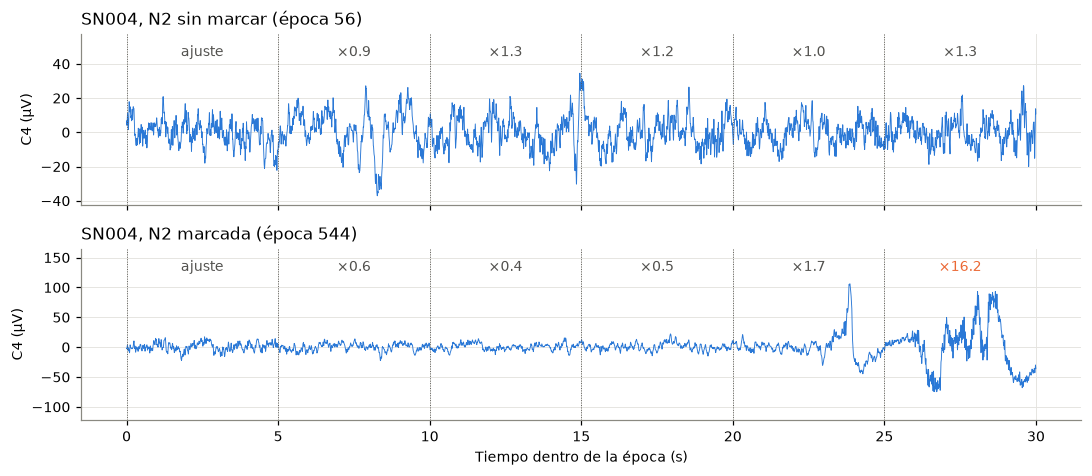

In [19]:
r = ejemplo()
prep = preprocesar(r, CFG)
c4 = segmentar(prep.registro.senales[EEG_C4], r.fs, r.n_epocas)
cambio = segmentacion.cambio_de_error(prep.registro)
marcada = cambio > segmentacion.CAMBIO_MAXIMO


def tipica(grupo):
    # La época del grupo con el cociente más cercano a la mediana del grupo.
    candidatas = np.flatnonzero(grupo)
    return candidatas[np.argmin(np.abs(cambio[candidatas] - np.median(cambio[candidatas])))]


elegidas = {"N2 sin marcar": tipica((r.estadios == N2) & ~marcada),
            "N2 marcada": tipica((r.estadios == N2) & marcada)}
t = np.arange(c4.shape[1]) / r.fs
fig, axs = plt.subplots(2, 1, figsize=(10, 4.4), sharex=True)
for ax, (titulo, i) in zip(axs, elegidas.items()):
    errores = segmentacion.errores_por_tramo(c4[i], r.fs)
    ax.plot(t, c4[i], c=AZUL, lw=0.6)
    techo = np.abs(c4[i]).max() * 1.15
    for k, e in enumerate(errores):
        ax.axvline(5 * k, c=GRIS, lw=0.6, ls=":")
        texto = "ajuste" if k == 0 else f"×{e:.1f}"
        ax.text(5 * k + 2.5, techo, texto, ha="center", va="bottom",
                color=NARANJA if e > segmentacion.CAMBIO_MAXIMO else GRIS)
    ax.set(ylim=(-techo, techo * 1.35), ylabel="C4 (µV)")
    ax.set_title(f"{r.id}, {titulo} (época {i})", loc="left")
axs[-1].set_xlabel("Tiempo dentro de la época (s)")
fig.tight_layout()
guardar(fig, "a_no_estacionaria_ejemplo")

En la época sin marcar el error de todos los tramos queda entre 0,9 y 1,3 veces el del primero. La señal cambia de forma de un tramo a otro, pero su espectro y su amplitud se mantienen y el modelo la sigue prediciendo bien.

En la época marcada los primeros 20 s son tranquilos y el cociente queda entre 0,4 y 1,7. Cerca de los 24 s aparece una onda grande, y en los últimos 5 s la señal pasa a tener deflexiones lentas de hasta 90 µV. Se marca ese tramo. La época siguiente es N1, así que lo más probable es que sea el comienzo de un despertar breve.

### Elección del umbral

Para ver cuánto depende la marca del umbral calculamos el mayor cociente de cada época en 12 pacientes. La figura muestra, para cada estadio, qué porcentaje de épocas quedaría marcado con cada umbral posible.

Porcentaje de épocas marcadas según el umbral, las 12 noches juntas


,W,N1,N2,N3,REM
umbral,,,,,
2,38.0,32.2,21.5,7.9,16.2
3,30.5,23.4,11.0,3.1,8.6
4,26.2,19.5,8.5,2.2,7.0
6,21.0,17.3,6.7,1.8,5.7
8,18.5,15.7,5.9,1.4,5.1


Épocas en que el primer tramo tiene más del doble de error que todos los demás (%)


,W,N1,N2,N3,REM
épocas (%),4.9,6.7,1.3,0.2,0.8


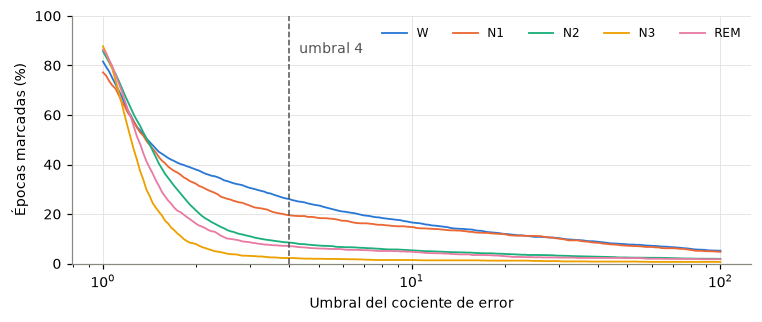

In [20]:
cambios, estadios = [], []
for r in pacientes(N_DETALLE):
    cambios.append(segmentacion.cambio_de_error(preprocesar(r, CFG).registro))
    estadios.append(r.estadios)
cambios, estadios = np.concatenate(cambios), np.concatenate(estadios)

fig, ax = plt.subplots(figsize=(7, 3))
umbrales = np.logspace(0, 2, 200)
for nombre, e in ESTADIOS_TABLA.items():
    ordenados = np.sort(cambios[estadios == e])
    marcadas = 100 * (1 - np.searchsorted(ordenados, umbrales, side="right") / len(ordenados))
    ax.plot(umbrales, marcadas, c=COLOR_ESTADIO[e], label=nombre)
ax.axvline(segmentacion.CAMBIO_MAXIMO, c=GRIS, ls="--", lw=1)
ax.text(segmentacion.CAMBIO_MAXIMO * 1.08, 85, "umbral 4", color=GRIS)
ax.set(xscale="log", ylim=(0, 100), xlabel="Umbral del cociente de error", ylabel="Épocas marcadas (%)")
ax.legend(ncols=5, fontsize=8, loc="upper right")
fig.tight_layout()
guardar(fig, "a_no_estacionaria_cociente")

print("Porcentaje de épocas marcadas según el umbral, las 12 noches juntas")
display(pd.DataFrame({umbral: {n: 100 * (cambios[estadios == e] > umbral).mean() for n, e in ESTADIOS_TABLA.items()}
                      for umbral in (2, 3, 4, 6, 8)}).T.rename_axis("umbral").round(1))
print("Épocas en que el primer tramo tiene más del doble de error que todos los demás (%)")
display(pd.Series({n: 100 * ((cambios[estadios == e] > 0) & (cambios[estadios == e] < 0.5)).mean()
                   for n, e in ESTADIOS_TABLA.items()}).to_frame("épocas (%)").T.round(1))

Entre 1 y 3 las curvas caen rápido. Ahí están la mayoría de las épocas, en las que el error varía un poco de un tramo a otro sin que la señal cambie de verdad. A partir de 4 las curvas de N2, N3 y REM se aplanan, y lo que queda son épocas con cambios grandes, de 10 o 100 veces. W y N1 siguen bajando despacio porque tienen muchos más cambios de verdad, como movimientos.

El método tiene una limitación. El primer tramo es la referencia, así que si el cambio está en los primeros 5 s, por ejemplo un movimiento que termina, el error de los tramos siguientes baja en vez de subir y la época no se marca. Eso pasa en el 5 % de las épocas de W y el 7 % de las de N1, y en menos del 1,5 % de las de N2, N3 y REM. La marca subestima un poco las épocas no estacionarias en W y N1.

**Decisión.** Usamos 4. Con 2 se marcaría el 22 % de N2 y el 8 % de N3, que son estadios estables, por las fluctuaciones normales del error. Con 4 se marca el 26 % de W, el 20 % de N1, el 8 % de N2, el 2 % de N3 y el 7 % de REM.

### ¿Sirve la marca?

Si la marca detecta cambios reales dentro de la época, tendría que aparecer más seguido en las épocas de transición, aquellas en que los técnicos anotaron un estadio distinto en la época anterior o en la siguiente. Y si las épocas marcadas mezclan dos estados, el clasificador tendría que acertar menos en ellas.

Lo medimos en los 56 pacientes de entrenamiento con las marcas y los descriptores guardados en el caché. Comparamos el estadio que da el clasificador de reglas, antes del suavizado, con el que anotaron los técnicos.

In [21]:
if USAR_DATOS_REALES:
    cfg_total = Config()
    tablas = [obtener_tabla(i, cfg_total) for i in IDS]  # Lee el caché de descriptores. Sin caché los calcula.
    modelo = ModeloEstadios(cfg_total.clasificacion).ajustar(tablas)
    filas = []
    for tabla in tablas:
        y = tabla.estadios
        # Época de transición, el estadio cambia respecto de la anterior o de la siguiente.
        transicion = np.r_[False, y[1:] != y[:-1]] | np.r_[y[:-1] != y[1:], False]
        prediccion = modelo.clasificar_epocas(tabla)[0]
        filas.append(pd.DataFrame({"estadio": y, "prediccion": prediccion, "marca": tabla.no_estacionaria,
                                   "transicion": transicion, "acierto": prediccion == y}))
    epocas = pd.concat(filas, ignore_index=True)
    epocas = epocas[epocas["estadio"].isin(ESTADIOS_TABLA.values())]
    codigos = epocas[["estadio", "prediccion"]].copy()  # Para el κ.
    nombre_de = {e: n for n, e in ESTADIOS_TABLA.items()}
    epocas["estadio"] = epocas["estadio"].map(nombre_de)
    epocas["prediccion"] = epocas["prediccion"].map(nombre_de)

    def resumen(g):
        return pd.Series({
            "marcadas (%)": 100 * g["marca"].mean(),
            "marcadas si es estable (%)": 100 * g.loc[~g["transicion"], "marca"].mean(),
            "marcadas si es transición (%)": 100 * g.loc[g["transicion"], "marca"].mean(),
            "acierto sin marca (%)": 100 * g.loc[~g["marca"], "acierto"].mean(),
            "acierto con marca (%)": 100 * g.loc[g["marca"], "acierto"].mean(),
        })

    tabla_marca = epocas.groupby("estadio").apply(resumen, include_groups=False).loc[list(ESTADIOS_TABLA)]
    tabla_marca.loc["Todas"] = resumen(epocas)
    print(f"{len(tablas)} pacientes de entrenamiento, {len(epocas)} épocas")
    display(tabla_marca.round(1))
    print("Solo épocas estables, acierto (%) sin marca y con marca")
    estables = epocas[~epocas["transicion"]]
    display(estables.groupby(["estadio", "marca"])["acierto"].mean().unstack().loc[list(ESTADIOS_TABLA)].mul(100).round(1))
    print("Épocas clasificadas como N3 (%), según el estadio real")
    display(epocas.assign(n3=epocas["prediccion"] == "N3").groupby(["estadio", "marca"])["n3"].mean()
            .unstack().loc[list(ESTADIOS_TABLA)].mul(100).round(1))
    sin_marca = codigos[~epocas["marca"]]
    print(f"κ sin suavizar, todas las épocas {metricas.kappa(codigos['estadio'], codigos['prediccion']):.3f}")
    print(f"κ sin suavizar, sin las marcadas {metricas.kappa(sin_marca['estadio'], sin_marca['prediccion']):.3f}")

56 pacientes de entrenamiento, 50856 épocas


,marcadas (%),marcadas si es estable (%),marcadas si es transición (%),acierto sin marca (%),acierto con marca (%)
estadio,,,,,
W,25.0,22.8,33.5,49.0,29.1
N1,15.9,10.6,17.9,41.2,16.6
N2,5.9,4.0,12.7,36.3,29.7
N3,2.7,1.5,11.0,49.2,67.3
REM,5.7,4.2,12.9,57.1,12.0
Todas,10.0,7.5,17.5,44.8,27.6


Solo épocas estables, acierto (%) sin marca y con marca


marca,False,True
estadio,,
W,49.7,31.8
N1,42.8,15.3
N2,38.4,30.4
N3,51.2,67.5
REM,58.3,15.3


Épocas clasificadas como N3 (%), según el estadio real


marca,False,True
estadio,,
W,10.3,32.8
N1,6.2,33.3
N2,10.9,31.2
N3,49.2,67.3
REM,2.8,27.1


κ sin suavizar, todas las épocas 0.289
κ sin suavizar, sin las marcadas 0.312


**La marca coincide con los cambios de estadio.** En todos los estadios las épocas de transición se marcan más que las estables. En N2 se pasa del 4 % al 13 %, en N3 del 1,5 % al 11 % y en REM del 4 % al 13 %. En W la diferencia es menor, del 23 % al 34 %, porque en vigilia hay muchos movimientos aunque no cambie el estadio.

**El clasificador acierta mucho menos en las épocas marcadas.** El acierto baja del 45 % al 28 % en general, y en REM del 57 % al 12 %. La diferencia se mantiene si miramos solo las épocas estables, así que no se explica solo por las transiciones. En REM estable el acierto baja del 58 % al 15 %.

**La excepción es N3, y ayuda a entender el resto.** En N3 las épocas marcadas aciertan más, 67 % contra 49 %. La última tabla muestra por qué. Entre las épocas marcadas, alrededor de un tercio de las de W, N1, N2 y REM se clasifica como N3, contra un 3 a 11 % de las no marcadas. La marca encuentra deflexiones grandes y lentas, como las de un movimiento o un despertar, y la regla de N3 las confunde con ondas lentas porque suben la potencia delta y el conteo de ondas de F4.

**Decisión.** La marca queda como información y las reglas no la usan. No sacamos las épocas marcadas de la evaluación, porque son justo las difíciles y el κ quedaría inflado. Sin ellas el κ sin suavizar pasaría de 0,289 a 0,312, una mejora chica porque son el 10 % de las épocas. Le pasamos al Frente C el resultado de la última tabla, porque muestra una fuente concreta de falsos N3 que podrían revisar en esa regla.

## 6. Variabilidad de la frecuencia cardíaca

Partimos de los latidos que pasaron el descarte por forma de la sección 4.1 y calculamos los intervalos RR. Después descartamos los intervalos fuera de 0,3 a 2 s y los que se alejan más de un 20 % de la mediana local, porque suelen abarcar un latido perdido o un latido prematuro que conservó la forma normal.

Sin esos latidos la serie queda con muestras irregulares, que es el caso que resuelve el periodograma de Lomb sin necesidad de interpolar. En una ventana de 5 min centrada en cada época medimos la potencia en HF y el cociente LF/HF. Para comparar pacientes usamos el percentil dentro de cada noche, igual que las reglas de clasificación.

,HF,LF/HF
estadio,,
W,52.9,50.2
N1,61.4,62.9
N2,50.0,48.0
N3,51.5,25.3
REM,30.1,70.4


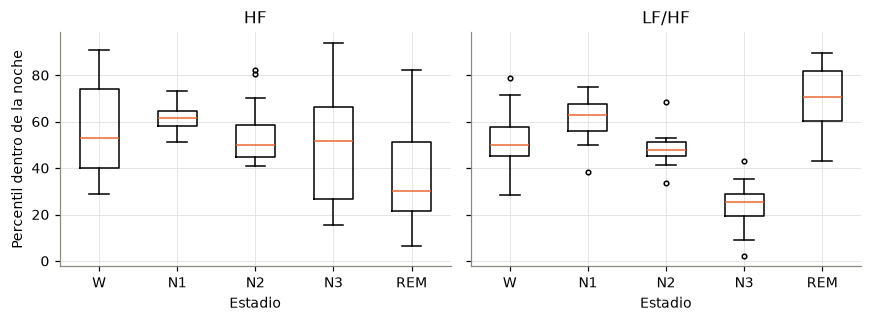

In [22]:
cfg_d = ConfigDescriptores()
filas = []
for r in pacientes(N_DETALLE):
    latidos = qrs.detectar_latidos(r.senales[ECG], r.fs)
    prep = RegistroPreprocesado(r, latidos, np.zeros(r.n_epocas, dtype=bool))
    matriz, nombres = hrv.descriptores_hrv(prep, cfg_d)
    percentiles = reglas.percentil_por_registro(matriz)
    for n, e in ESTADIOS_TABLA.items():
        if (r.estadios == e).any():
            filas.append({"paciente": r.id, "estadio": n, "HF": np.median(percentiles[r.estadios == e, 0]),
                          "LF/HF": np.median(percentiles[r.estadios == e, 1])})
hrv_estadio = pd.DataFrame(filas)
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, medida in zip(axs, ("HF", "LF/HF")):
    ax.boxplot([hrv_estadio.loc[hrv_estadio["estadio"] == n, medida] for n in ESTADIOS_TABLA],
               tick_labels=list(ESTADIOS_TABLA), widths=0.5, medianprops={"color": NARANJA}, flierprops={"markersize": 3})
    ax.set(title=medida, xlabel="Estadio")
axs[0].set_ylabel("Percentil dentro de la noche")
fig.tight_layout()
guardar(fig, "a_hrv_por_estadio")
hrv_estadio.groupby("estadio")[["HF", "LF/HF"]].median().loc[list(ESTADIOS_TABLA)].round(1)

LF/HF baja en N3, con percentil 25, y sube en REM, con percentil 70, como se espera por el predominio parasimpático del sueño profundo y simpático de REM. HF baja en REM, pero no sube en N3, así que aporta menos que el cociente. La regla de REM usa LF/HF.

## 7. Resultado de la cadena completa

La figura muestra una misma época de F4 después de cada etapa.

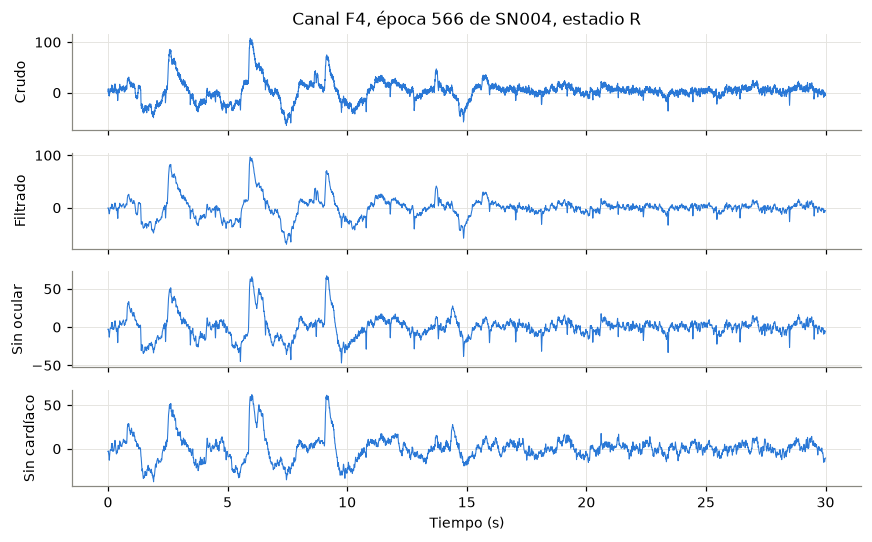

In [23]:
r = ejemplo()
prep = preprocesar(r, CFG, guardar_intermedios=True)
n = int(30 * r.fs)
t = np.arange(n) / r.fs
candidatas = np.flatnonzero(r.estadios == R) if (r.estadios == R).any() else np.arange(r.n_epocas)
epoca = candidatas[len(candidatas) // 2]
tramo = slice(epoca * n, (epoca + 1) * n)
etapas = {"crudo": "Crudo", "filtrado": "Filtrado", "sin_ocular": "Sin ocular", "sin_cardiaco": "Sin cardíaco"}
fig, axs = plt.subplots(len(etapas), 1, figsize=(8, 5), sharex=True)
for ax, (clave, nombre) in zip(axs, etapas.items()):
    ax.plot(t, prep.intermedios[clave][EEG_F4][tramo], c=AZUL, lw=0.7)
    ax.set_ylabel(nombre)
axs[0].set_title(f"Canal F4, época {epoca} de {r.id}, estadio {NOMBRES_ESTADIOS[r.estadios[epoca]]}")
axs[-1].set_xlabel("Tiempo (s)")
fig.tight_layout()
guardar(fig, "a_etapas")